In [2]:
# W2D1: Feature Engineering & Encoding

import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.feature_selection import SelectKBest, f_classif

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
print("W2D1 started successfully!")

W2D1 started successfully!


In [4]:
# Load FinWise dataset

df = pd.read_csv("../finwise_loan_applications.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset shape: (1000, 13)

Columns:
['application_id', 'age', 'income_annual_inr', 'employment_type', 'employment_years', 'existing_loans', 'existing_emi_inr', 'credit_score', 'loan_amount_inr', 'loan_purpose', 'ltv_ratio', 'dti_ratio', 'default_flag']


,application_id,age,income_annual_inr,employment_type,employment_years,existing_loans,existing_emi_inr,credit_score,loan_amount_inr,loan_purpose,ltv_ratio,dti_ratio,default_flag
0,APP-0001,47,840000,self_employed,20,1,6772,681,500000,medical,0.61,0.15,0
1,APP-0002,56,300000,contract,7,3,44496,815,2500000,personal,0.52,2.58,1
2,APP-0003,45,2400000,contract,7,1,10560,596,500000,home,0.92,0.07,0
3,APP-0004,27,840000,government,13,0,0,548,2500000,home,0.63,0.29,0
4,APP-0005,56,300000,contract,17,1,12920,654,250000,vehicle,0.92,0.60,0


In [5]:
# Identify categorical columns

categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())

Categorical columns:
['application_id', 'employment_type', 'loan_purpose']

application_id:
<ArrowStringArray>
['APP-0001', 'APP-0002', 'APP-0003', 'APP-0004', 'APP-0005', 'APP-0006',
 'APP-0007', 'APP-0008', 'APP-0009', 'APP-0010',
 ...
 'APP-0991', 'APP-0992', 'APP-0993', 'APP-0994', 'APP-0995', 'APP-0996',
 'APP-0997', 'APP-0998', 'APP-0999', 'APP-1000']
Length: 1000, dtype: str

employment_type:
<ArrowStringArray>
['self_employed', 'contract', 'government', 'salaried']
Length: 4, dtype: str

loan_purpose:
<ArrowStringArray>
['medical', 'personal', 'home', 'vehicle', 'business', 'education']
Length: 6, dtype: str


C:\Users\ravik\AppData\Local\Temp\ipykernel_21108\1630042720.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()


In [6]:
# Identify categorical columns

categorical_cols = df.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())

Categorical columns:
['application_id', 'employment_type', 'loan_purpose']

application_id:
<ArrowStringArray>
['APP-0001', 'APP-0002', 'APP-0003', 'APP-0004', 'APP-0005', 'APP-0006',
 'APP-0007', 'APP-0008', 'APP-0009', 'APP-0010',
 ...
 'APP-0991', 'APP-0992', 'APP-0993', 'APP-0994', 'APP-0995', 'APP-0996',
 'APP-0997', 'APP-0998', 'APP-0999', 'APP-1000']
Length: 1000, dtype: str

employment_type:
<ArrowStringArray>
['self_employed', 'contract', 'government', 'salaried']
Length: 4, dtype: str

loan_purpose:
<ArrowStringArray>
['medical', 'personal', 'home', 'vehicle', 'business', 'education']
Length: 6, dtype: str


In [7]:
# LabelEncoder

label_encoder = LabelEncoder()

df_label = df.copy()

df_label["employment_type_encoded"] = label_encoder.fit_transform(
    df_label["employment_type"]
)

print("LabelEncoder mapping:")

for category, encoded_value in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{category} -> {encoded_value}")

df_label[
    ["employment_type", "employment_type_encoded"]
].head()

LabelEncoder mapping:
contract -> 0
government -> 1
salaried -> 2
self_employed -> 3


,employment_type,employment_type_encoded
0,self_employed,3
1,contract,0
2,contract,0
3,government,1
4,contract,0


In [8]:
# OneHotEncoder

onehot_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

employment_encoded = onehot_encoder.fit_transform(
    df[["employment_type"]]
)

employment_columns = onehot_encoder.get_feature_names_out(
    ["employment_type"]
)

df_onehot = pd.DataFrame(
    employment_encoded,
    columns=employment_columns,
    index=df.index
)

print("OneHotEncoder columns:")
print(employment_columns)

df_onehot.head()

OneHotEncoder columns:
['employment_type_contract' 'employment_type_government'
 'employment_type_salaried' 'employment_type_self_employed']


,employment_type_contract,employment_type_government,employment_type_salaried,employment_type_self_employed
0,0.0,0.0,0.0,1.0
1,1.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0
4,1.0,0.0,0.0,0.0


In [9]:
# OrdinalEncoder

ordinal_encoder = OrdinalEncoder(
    categories=[[
        "contract",
        "self_employed",
        "salaried",
        "government"
    ]]
)

df_ordinal = df.copy()

df_ordinal["employment_type_ordinal"] = ordinal_encoder.fit_transform(
    df_ordinal[["employment_type"]]
)

print("OrdinalEncoder mapping:")

for category, encoded_value in zip(
    ordinal_encoder.categories_[0],
    range(len(ordinal_encoder.categories_[0]))
):
    print(f"{category} -> {encoded_value}")

df_ordinal[
    ["employment_type", "employment_type_ordinal"]
].head()

OrdinalEncoder mapping:
contract -> 0
self_employed -> 1
salaried -> 2
government -> 3


,employment_type,employment_type_ordinal
0,self_employed,1.0
1,contract,0.0
2,contract,0.0
3,government,3.0
4,contract,0.0


In [10]:
# Encoding Methods - Trade-offs

encoding_notes = pd.DataFrame({
    "Method": [
        "LabelEncoder",
        "OneHotEncoder",
        "OrdinalEncoder"
    ],
    "Advantage": [
        "Simple and compact representation",
        "Does not create an artificial order",
        "Useful when categories have a meaningful order"
    ],
    "Trade_off": [
        "May create a false numerical relationship between categories",
        "Creates more columns when there are many categories",
        "Can be misleading if the categories do not have a real order"
    ]
})

encoding_notes

,Method,Advantage,Trade_off
0,LabelEncoder,Simple and compact representation,May create a false numerical relationship betw...
1,OneHotEncoder,Does not create an artificial order,Creates more columns when there are many categ...
2,OrdinalEncoder,Useful when categories have a meaningful order,Can be misleading if the categories do not hav...


In [11]:
# Select numerical features for scaling

numeric_features = [
    "age",
    "income_annual_inr",
    "employment_years",
    "existing_loans",
    "existing_emi_inr",
    "credit_score",
    "loan_amount_inr",
    "ltv_ratio",
    "dti_ratio"
]

X_numeric = df[numeric_features].copy()

print("Numerical features:")
print(numeric_features)

print("\nShape:", X_numeric.shape)

X_numeric.head()

Numerical features:
['age', 'income_annual_inr', 'employment_years', 'existing_loans', 'existing_emi_inr', 'credit_score', 'loan_amount_inr', 'ltv_ratio', 'dti_ratio']

Shape: (1000, 9)


,age,income_annual_inr,employment_years,existing_loans,existing_emi_inr,credit_score,loan_amount_inr,ltv_ratio,dti_ratio
0,47,840000,20,1,6772,681,500000,0.61,0.15
1,56,300000,7,3,44496,815,2500000,0.52,2.58
2,45,2400000,7,1,10560,596,500000,0.92,0.07
3,27,840000,13,0,0,548,2500000,0.63,0.29
4,56,300000,17,1,12920,654,250000,0.92,0.60


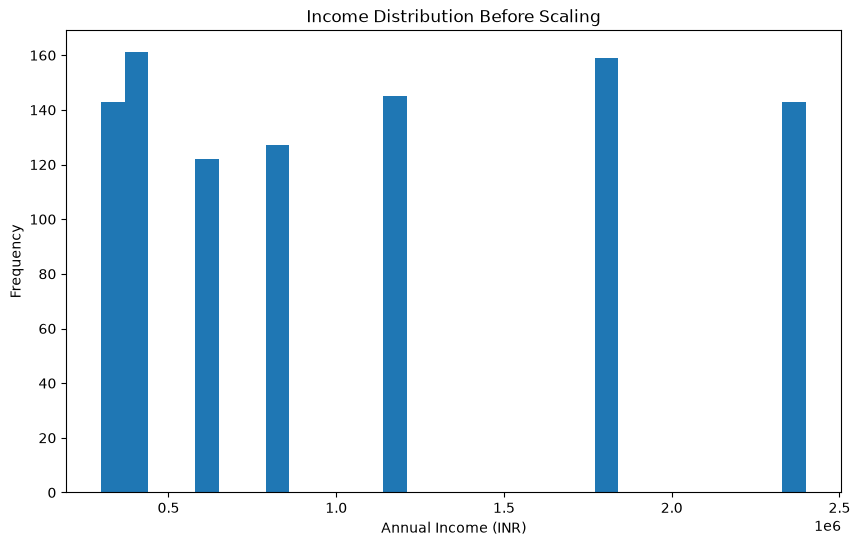

In [12]:
# Distribution Before Scaling

plt.figure(figsize=(10, 6))

plt.hist(
    X_numeric["income_annual_inr"],
    bins=30
)

plt.title("Income Distribution Before Scaling")
plt.xlabel("Annual Income (INR)")
plt.ylabel("Frequency")

plt.show()

In [13]:
# StandardScaler

standard_scaler = StandardScaler()

X_standard = standard_scaler.fit_transform(X_numeric)

X_standard = pd.DataFrame(
    X_standard,
    columns=numeric_features
)

print("StandardScaler applied successfully!")

X_standard.head()

StandardScaler applied successfully!


,age,income_annual_inr,employment_years,existing_loans,existing_emi_inr,credit_score,loan_amount_inr,ltv_ratio,dti_ratio
0,0.587425,-0.349930,1.609044,-0.473465,-0.595679,-0.006206,-0.627273,-0.382272,-0.657025
1,1.425539,-1.094461,-0.662630,1.361672,2.579361,1.687582,0.528032,-0.957309,4.382658
2,0.401177,1.800939,-0.662630,-0.473465,-0.276862,-1.080624,-0.627273,1.598412,-0.822941
3,-1.275051,-0.349930,0.385835,-1.391034,-1.165644,-1.687354,0.528032,-0.254486,-0.366673
4,1.425539,-1.094461,1.084812,-0.473465,-0.078233,-0.347492,-0.771686,1.598412,0.276249


In [14]:
# MinMaxScaler

minmax_scaler = MinMaxScaler()

X_minmax = minmax_scaler.fit_transform(X_numeric)

X_minmax = pd.DataFrame(
    X_minmax,
    columns=numeric_features
)

print("MinMaxScaler applied successfully!")

X_minmax.head()

MinMaxScaler applied successfully!


,age,income_annual_inr,employment_years,existing_loans,existing_emi_inr,credit_score,loan_amount_inr,ltv_ratio,dti_ratio
0,0.694444,0.257143,1.000000,0.333333,0.150569,0.510067,0.081633,0.381818,0.049020
1,0.944444,0.000000,0.315789,1.000000,0.989328,0.809843,0.489796,0.218182,0.843137
2,0.638889,1.000000,0.315789,0.333333,0.234792,0.319911,0.081633,0.945455,0.022876
3,0.138889,0.257143,0.631579,0.000000,0.000000,0.212528,0.489796,0.418182,0.094771
4,0.944444,0.000000,0.842105,0.333333,0.287264,0.449664,0.030612,0.945455,0.196078


In [15]:
# RobustScaler

robust_scaler = RobustScaler()

X_robust = robust_scaler.fit_transform(X_numeric)

X_robust = pd.DataFrame(
    X_robust,
    columns=numeric_features
)

print("RobustScaler applied successfully!")

X_robust.head()

RobustScaler applied successfully!


,age,income_annual_inr,employment_years,existing_loans,existing_emi_inr,credit_score,loan_amount_inr,ltv_ratio,dti_ratio
0,0.328767,0.000000,0.9,-1.0,-0.297465,0.009259,-0.222222,-0.192308,-0.294118
1,0.821918,-0.391304,-0.4,1.0,1.865732,1.250000,0.666667,-0.538462,4.470588
2,0.219178,1.130435,-0.4,-1.0,-0.080251,-0.777778,-0.222222,1.000000,-0.450980
3,-0.767123,0.000000,0.2,-2.0,-0.685790,-1.222222,0.666667,-0.115385,-0.019608
4,0.821918,-0.391304,0.6,-1.0,0.055078,-0.240741,-0.333333,1.000000,0.588235


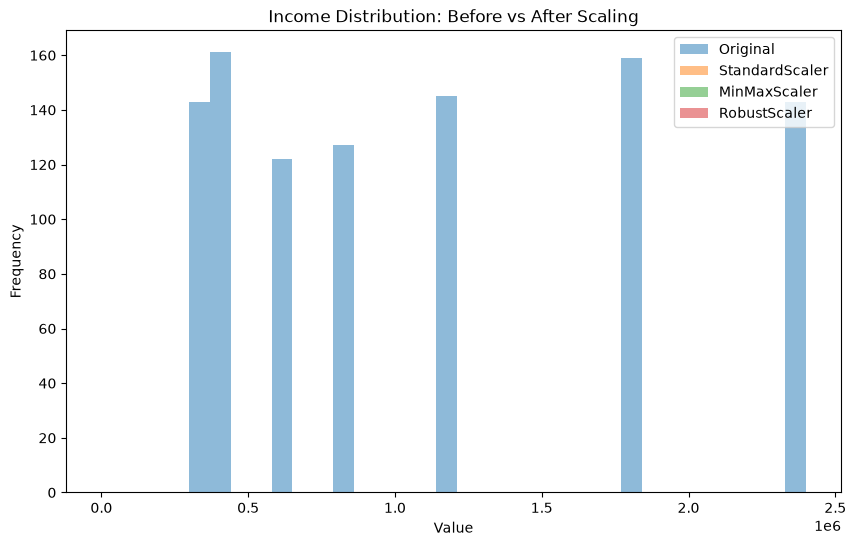

In [16]:
# Compare distributions before and after scaling

plt.figure(figsize=(10, 6))

plt.hist(
    X_numeric["income_annual_inr"],
    bins=30,
    alpha=0.5,
    label="Original"
)

plt.hist(
    X_standard["income_annual_inr"],
    bins=30,
    alpha=0.5,
    label="StandardScaler"
)

plt.hist(
    X_minmax["income_annual_inr"],
    bins=30,
    alpha=0.5,
    label="MinMaxScaler"
)

plt.hist(
    X_robust["income_annual_inr"],
    bins=30,
    alpha=0.5,
    label="RobustScaler"
)

plt.title("Income Distribution: Before vs After Scaling")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.legend()

plt.show()

In [17]:
# SelectKBest - Top 5 Features

X = df[numeric_features]
y = df["default_flag"]

selector = SelectKBest(
    score_func=f_classif,
    k=5
)

X_selected = selector.fit_transform(X, y)

selected_features = X.columns[selector.get_support()]

feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "F_Score": selector.scores_
}).sort_values(
    by="F_Score",
    ascending=False
)

print("Top 5 Features:")
print(feature_scores.head(5).to_string(index=False))

Top 5 Features:
          Feature    F_Score
        dti_ratio 774.059175
income_annual_inr 169.959274
 existing_emi_inr  91.597428
  loan_amount_inr  84.661351
   existing_loans  59.617533


In [18]:
# Why the Top 5 Features Matter

feature_explanations = {
    "dti_ratio": "Debt-to-income ratio indicates how much of an applicant's income is committed to debt obligations. A higher ratio can be associated with greater repayment pressure.",
    
    "income_annual_inr": "Annual income represents the applicant's earning capacity and can affect their ability to repay a loan.",
    
    "existing_emi_inr": "Existing EMI indicates the applicant's current monthly debt repayment burden and can affect their capacity to take on additional debt.",
    
    "loan_amount_inr": "Loan amount represents the size of the requested borrowing and can influence the overall repayment burden and credit risk.",
    
    "existing_loans": "The number of existing loans indicates the applicant's current borrowing commitments and may provide information about their existing debt exposure."
}

for feature in feature_scores.head(5)["Feature"]:
    print(f"\n{feature}")
    print(feature_explanations[feature])


dti_ratio
Debt-to-income ratio indicates how much of an applicant's income is committed to debt obligations. A higher ratio can be associated with greater repayment pressure.

income_annual_inr
Annual income represents the applicant's earning capacity and can affect their ability to repay a loan.

existing_emi_inr
Existing EMI indicates the applicant's current monthly debt repayment burden and can affect their capacity to take on additional debt.

loan_amount_inr
Loan amount represents the size of the requested borrowing and can influence the overall repayment burden and credit risk.

existing_loans
The number of existing loans indicates the applicant's current borrowing commitments and may provide information about their existing debt exposure.


In [19]:
# W2D1 Final Summary

print("W2D1: Feature Engineering & Encoding")
print("=" * 45)

print("\nEncoding Methods:")
print("1. LabelEncoder - converts categories into integer labels.")
print("2. OneHotEncoder - creates separate binary columns for categories.")
print("3. OrdinalEncoder - converts ordered categories into numerical values.")

print("\nScaling Methods:")
print("1. StandardScaler - standardizes features around mean 0 and standard deviation 1.")
print("2. MinMaxScaler - scales features to a fixed range, usually 0 to 1.")
print("3. RobustScaler - uses median and IQR and is more resistant to outliers.")

print("\nFeature Selection:")
print("SelectKBest was used with ANOVA F-test to identify the top 5 features.")

print("\nTop 5 Features:")
for feature in feature_scores.head(5)["Feature"]:
    print("-", feature)

print("\nW2D1 practical tasks completed successfully!")

W2D1: Feature Engineering & Encoding

Encoding Methods:
1. LabelEncoder - converts categories into integer labels.
2. OneHotEncoder - creates separate binary columns for categories.
3. OrdinalEncoder - converts ordered categories into numerical values.

Scaling Methods:
1. StandardScaler - standardizes features around mean 0 and standard deviation 1.
2. MinMaxScaler - scales features to a fixed range, usually 0 to 1.
3. RobustScaler - uses median and IQR and is more resistant to outliers.

Feature Selection:
SelectKBest was used with ANOVA F-test to identify the top 5 features.

Top 5 Features:
- dti_ratio
- income_annual_inr
- existing_emi_inr
- loan_amount_inr
- existing_loans

W2D1 practical tasks completed successfully!
